In [78]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("heart.csv")

print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())


Shape: (1025, 14)

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [11]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [72]:
x_cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
X = df[x_cols]
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2


In [73]:

# Normalization
normalizer = MinMaxScaler()
normalized = normalizer.fit_transform(X)

# Standardization
standardizer = StandardScaler()
standardized = standardizer.fit_transform(X)

print("Normalized Data:")
print(normalized)

print("Standardized Data:")
print(standardized)


Normalized Data:
[[0.47916667 1.         0.         ... 1.         0.5        1.        ]
 [0.5        1.         0.         ... 0.         0.         1.        ]
 [0.85416667 1.         0.         ... 0.         0.         1.        ]
 ...
 [0.375      1.         0.         ... 0.5        0.25       0.66666667]
 [0.4375     0.         0.         ... 1.         0.         0.66666667]
 [0.52083333 1.         0.         ... 0.5        0.25       1.        ]]
Standardized Data:
[[-0.26843658  0.66150409 -0.91575542 ...  0.99543334  1.20922066
   1.08985168]
 [-0.15815703  0.66150409 -0.91575542 ... -2.24367514 -0.73197147
   1.08985168]
 [ 1.71659547  0.66150409 -0.91575542 ... -2.24367514 -0.73197147
   1.08985168]
 ...
 [-0.81983438  0.66150409 -0.91575542 ... -0.6241209   0.23862459
  -0.52212231]
 [-0.4889957  -1.51170646 -0.91575542 ...  0.99543334 -0.73197147
  -0.52212231]
 [-0.04787747  0.66150409 -0.91575542 ... -0.6241209   0.23862459
   1.08985168]]


In [74]:
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1025, 13)
y shape: (1025,)


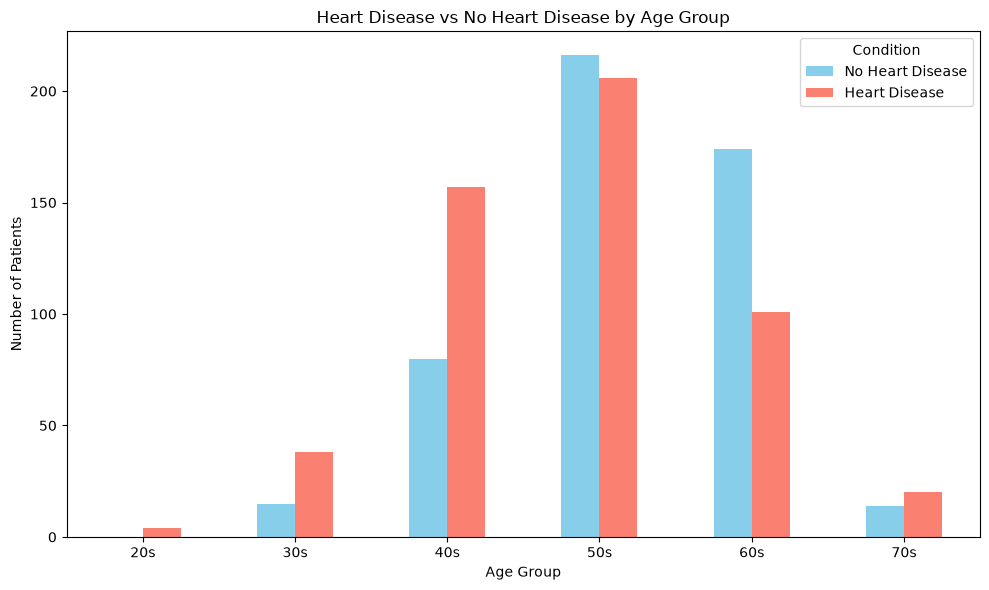

In [75]:
# Define age groups
bins = [20, 30, 40, 50, 60, 70, 80]
labels = ['20s', '30s', '40s', '50s', '60s', '70s']

# Create a new age group column
df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels,
    right=False
)

# Count patients by age group and target
age_target = df.groupby(
    ['age_group', 'target'], observed=False
).size().unstack(fill_value=0)

# Rename columns
age_target.columns = ['No Heart Disease', 'Heart Disease']

# Plot grouped bar chart
age_target.plot(kind='bar', figsize=(10, 6), color=['skyblue', 'salmon'])

plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.title('Heart Disease vs No Heart Disease by Age Group')
plt.legend(title='Condition')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


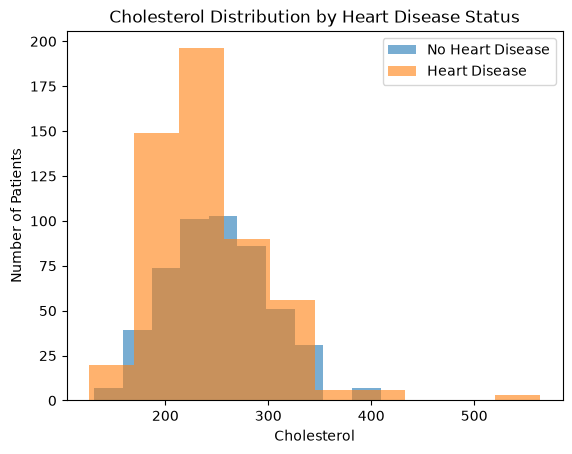

In [55]:
# Separate cholesterol values by target
no_disease = df[df['target'] == 0]['chol']
heart_disease = df[df['target'] == 1]['chol']

# Plot histograms
plt.hist(no_disease, bins=10, alpha=0.6, label='No Heart Disease')
plt.hist(heart_disease, bins=10, alpha=0.6, label='Heart Disease')

plt.xlabel('Cholesterol')
plt.ylabel('Number of Patients')
plt.title('Cholesterol Distribution by Heart Disease Status')
plt.legend()
plt.show()

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2,random_state=1)

LogReg = LogisticRegression(max_iter=1000, random_state=45)
LogReg.fit(X_train,y_train)
y_pred = LogReg.predict(X_test)
LogReg.score(X_test,y_test)

0.8097560975609757

In [77]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.4f}")
print(f"Precision : {precision_score(y_test,y_pred):.4f}")
print(f"Recall : {recall_score(y_test,y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test,y_pred):.4f}")

Accuracy : 0.8098
Precision : 0.7478
Recall : 0.8958
F1 Score : 0.8152


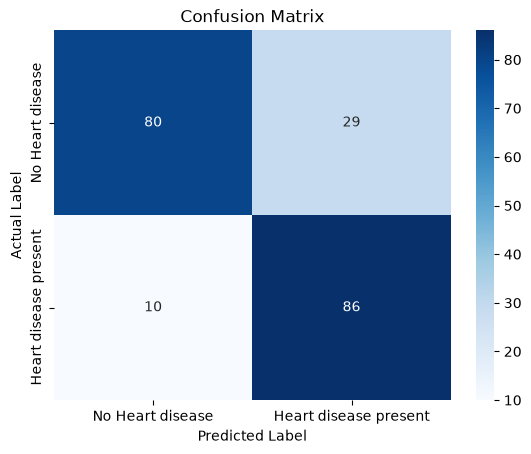

Confusion Matrix:
[[80 29]
 [10 86]]


In [81]:
cm = confusion_matrix(y_test,y_pred)
# Visualize the confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Heart disease", "Heart disease present"],
    yticklabels=["No Heart disease", "Heart disease present"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

# Print performance metrics
print("Confusion Matrix:")
print(cm)

In [83]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Heart disease", "Heart disease present"]
))


Classification Report:
                       precision    recall  f1-score   support

     No Heart disease       0.89      0.73      0.80       109
Heart disease present       0.75      0.90      0.82        96

             accuracy                           0.81       205
            macro avg       0.82      0.81      0.81       205
         weighted avg       0.82      0.81      0.81       205

